student_id          0
age                 0
study_hours         0
attendance          0
previous_marks      0
assignment_score    0
result              0
dtype: int64


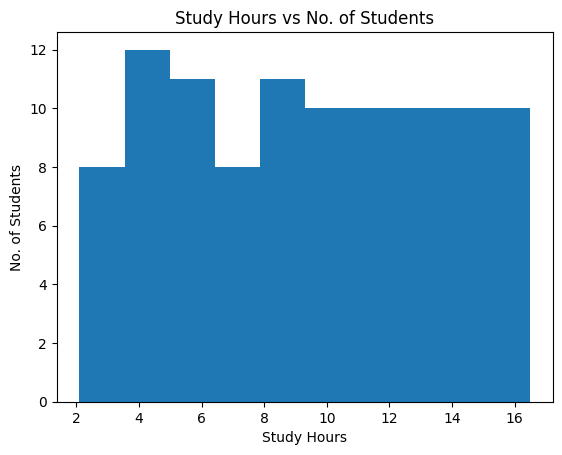

,student_id,age,study_hours,attendance,previous_marks,assignment_score,result,performance_score
0,STU001,19.0,4.4,59.0,48.0,51,Fail,42.78
1,STU002,18.0,15.7,98.0,90.0,92,Pass,77.64
2,STU003,21.0,11.2,85.0,74.0,78,Pass,65.19
3,STU004,20.0,8.5,74.0,62.0,65,Pass,55.05
4,STU005,17.0,2.1,45.0,35.0,38,Fail,31.67


0     0
1     1
2     1
3     1
4     0
     ..
95    0
96    1
97    1
98    1
99    1
Name: result, Length: 100, dtype: int64
(80, 5)
(20, 5)
(80,)
(20,)
[1 1 1 1 1 1 1 1 1 1 1 0 1 1 0 0 1 1 1 1]
Accuracy: 0.95
Precision: 0.9411764705882353


In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,precision_score
from sklearn.metrics import recall_score , f1_score
from sklearn.metrics import confusion_matrix,classification_report

data=pd.read_csv('student_dataset.csv')
# print(data)
# print(data.head())
# print(data.shape)
# print(data.columns)
# print(data.dtypes)
# print(data.describe)
# print(data.isnull().sum())
# print(data.duplicated().sum())

data["student_id"]=data['student_id'].fillna("No Id")
data["age"]=data['age'].fillna(data['age'].mean())
data["study_hours"]=data['study_hours'].fillna(data['study_hours'].mean())
data["attendance"]=data['attendance'].fillna(data['attendance'].mean())
data["previous_marks"]=data['previous_marks'].fillna(data['previous_marks'].mean())
data["result"]=data['result'].fillna("Pass")
print(data.isnull().sum())


plt.hist(data['study_hours'])
plt.xlabel('Study Hours')
plt.ylabel('No. of Students')
plt.title('Study Hours vs No. of Students')
plt.show()

data["performance_score"] = (0.3 * data["previous_marks"] +
                            0.2 * data["study_hours"] +
                            0.25 * data["attendance"] +
                            0.25 * data["assignment_score"])

display(data.head())

X=data[["study_hours","attendance",'previous_marks',"assignment_score","performance_score"]]
y=data['result']
y=y.map({'Pass':1,'Fail':0})

print(y)


X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)


model=DecisionTreeClassifier(max_depth=3,random_state=42)

model.fit(X_train,y_train)

y_pred=model.predict(X_test)
print(y_pred)
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)
precision=precision_score(y_test,y_pred)
print("Precision:",precision)

